# Prototype: from a before/after satellite image pair to reconstruction carbon and cost

This notebook **uses** the finished models. How they were built, trained, chosen and tested is in `xBD_damage_to_carbon_cost.ipynb`; the code used here lives in `xbd_pipeline.py`, and Section 9d of the main notebook checks that it reproduces the main notebook's numbers.

**What it does with one image pair (before and after the disaster):**

| Step | How | Output shown |
|---|---|---|
| 1. Find buildings | building map from the multi-task U-Net (main notebook Section 3c-ii); touching building pixels form one building | outlines on the before image |
| 2. Judge damage | pretrained crop classifier `effnet_ce+tier3_cosine` (Section 3c): before and after crop of each building | damage map and counts |
| 3. Materials, carbon, cost | region's construction mix from GEM (Layer 1), material intensities from RASMI, carbon factors from ICE, rebuild % by damage class (Sections 4-7) | per-building table and totals |

**What the numbers mean (stated with every result):** carbon is *embodied material carbon* of rebuilding, by two routes (RASMI × ICE, and GEM's own figure); cost is *building replacement cost* from GEM (as built, including labour, excluding contents). Both are regional averages applied to each building, not surveys of individual buildings.

**Before using it:** the region must be one GEM covers in `reference_data/gem_exposure_adm1.csv`, and images must be about 0.47 m per pixel (xBD resolution) unless `PIXEL_SIZE_M` is changed. The ICE factor file must be built from your own ICE download (see README).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
import xbd_pipeline as xp

# ---------------- INPUTS: edit these ----------------
BEFORE_IMAGE = Path("xBD/test/images/hurricane-harvey_00000250_pre_disaster.png")
AFTER_IMAGE = Path("xBD/test/images/hurricane-harvey_00000250_post_disaster.png")
REGION = xp.DISASTER_REGION["hurricane-harvey"]   # or any (country ISO3, GEM state) pair, e.g. ("USA", "Texas")
xp.PIXEL_SIZE_M = 0.47                            # metres per pixel of the images
# -----------------------------------------------------

print("Region:", REGION, "| RASMI region:", xp.COUNTRY_RASMI_REGION[REGION[0]], "| pixel size:", xp.PIXEL_SIZE_M, "m")

Region: ('USA', 'Texas') | RASMI region: OECD_USA | pixel size: 0.47 m


**The assumptions this run uses.** Rebuild percentage by damage class, and what one m² of building footprint means in the chosen region (from the region's GEM construction mix, RASMI and ICE). Change the inputs above and these change with them.

In [2]:
factors = xp.region_factors(*REGION)
display(pd.Series(xp.REBUILD_PCT, name="share of the building rebuilt").to_frame())
per_m2 = pd.DataFrame({"per m2 of footprint": factors}).rename(index={
    "floor_m2": "floor area (m2)", "gem_kgco2e": "embodied carbon, GEM (kgCO2e)", "cost_usd": "replacement cost (USD)",
    "ice_kgco2e": "embodied carbon, RASMI x ICE (kgCO2e)"})
per_m2.round(2)

,share of the building rebuilt
no-damage,0.00
minor-damage,0.15
major-damage,0.60
destroyed,1.00


,per m2 of footprint
floor area (m2),1.51
"embodied carbon, GEM (kgCO2e)",296.30
replacement cost (USD),2617.97
kg_aluminum,0.74
kg_brick,305.77
kg_concrete,532.34
kg_glass,7.15
kg_plastics,1.81
kg_steel,23.55
kg_wood,81.10


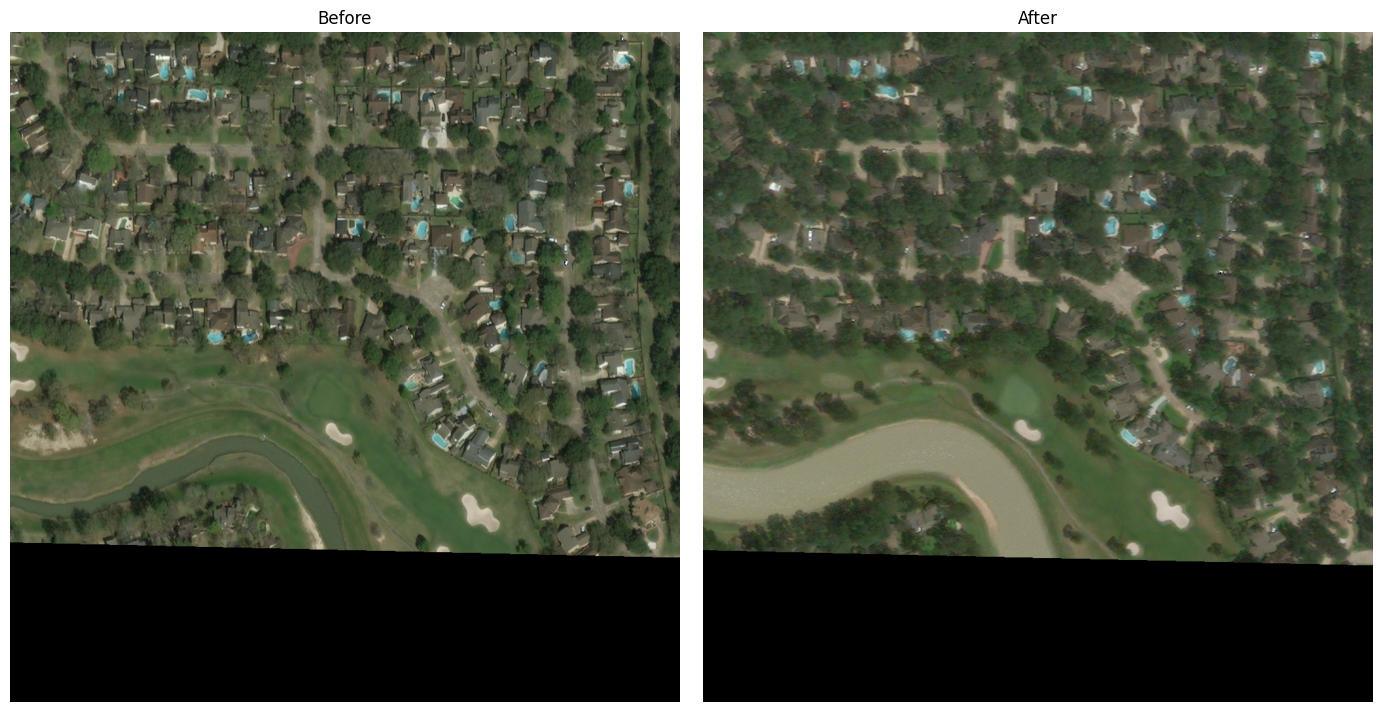

In [3]:
finder, damage_model = xp.load_models()
before, after = xp.load_image(BEFORE_IMAGE), xp.load_image(AFTER_IMAGE)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, image, title in zip(axes, (before, after), ("Before", "After")):
    ax.imshow(image); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

**Step 1 — find buildings.** Each separate patch of building pixels counts as one building. Patches smaller than `xp.MIN_BUILDING_PIXELS` are ignored as noise. Buildings that touch are counted as one.

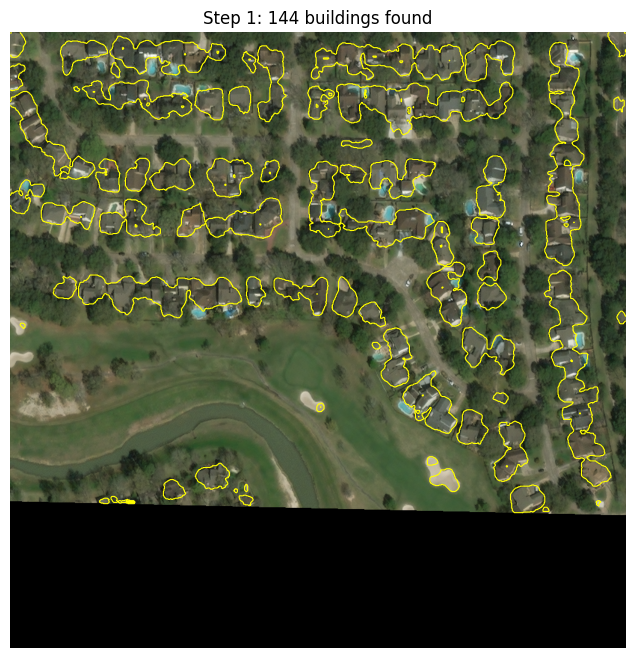

Total footprint found: 39,503 m2


In [4]:
buildings, labelled = xp.find_buildings(finder, before, after)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(before); ax.contour(labelled > 0, levels=[0.5], colors="yellow", linewidths=0.8)
ax.set_title(f"Step 1: {len(buildings)} buildings found"); ax.axis("off"); plt.show()
print(f"Total footprint found: {buildings['footprint_m2'].sum():,.0f} m2")

**Step 2 — judge damage.** Each building's before and after crop goes to the damage classifier. Colours: green no damage, yellow minor, orange major, red destroyed.

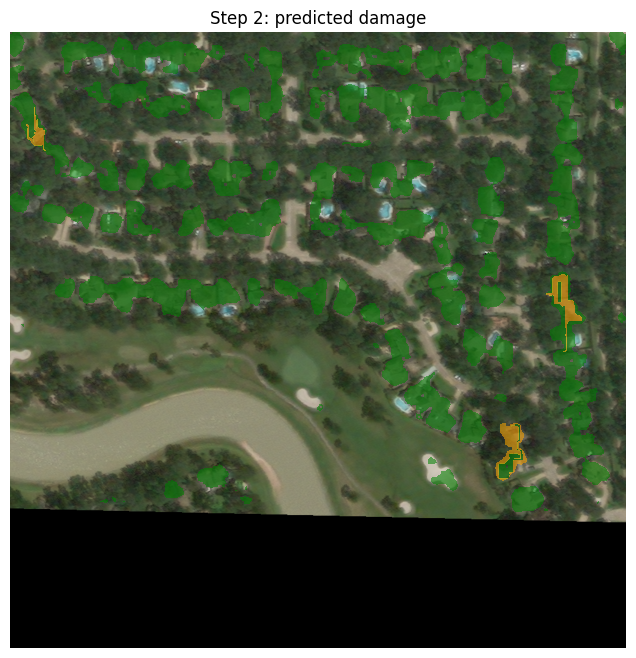

,buildings
damage_class,
no-damage,141
minor-damage,0
major-damage,3
destroyed,0


In [5]:
buildings["damage_class"] = xp.judge_damage(damage_model, before, after, buildings)
damage_map = np.zeros(labelled.shape, dtype=int)
for b in buildings.itertuples():
    damage_map[labelled == b.building] = xp.DAMAGE_CLASSES.index(b.damage_class) + 1
colours = ListedColormap(["none", "green", "gold", "orange", "red"])
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(after); ax.imshow(np.ma.masked_equal(damage_map, 0), cmap=colours, vmin=0, vmax=4, alpha=0.55)
ax.set_title("Step 2: predicted damage"); ax.axis("off"); plt.show()
buildings["damage_class"].value_counts().reindex(xp.DAMAGE_CLASSES, fill_value=0).to_frame("buildings")

**Step 3 — materials, carbon and cost.** Rebuilt area = footprint × rebuild %. Carbon and cost follow from the region's per-m² figures above. The table lists the ten buildings with the largest carbon, then the totals.

In [6]:
result = xp.estimate(buildings, factors)
display(result.sort_values("carbon_A_tco2e", ascending=False).head(10)[
    ["building", "footprint_m2", "damage_class", "rebuild_pct", "rebuilt_floor_m2", "carbon_A_tco2e", "carbon_B_tco2e", "replacement_cost_usd"]].round(1))

summary = pd.Series({
    "buildings found": len(result),
    "buildings needing rebuilding work": int((result["rebuild_pct"] > 0).sum()),
    "rebuilt floor area (m2)": result["rebuilt_floor_m2"].sum(),
    "embodied material carbon, RASMI x ICE (tCO2e)": result["carbon_A_tco2e"].sum(),
    "embodied material carbon, GEM (tCO2e)": result["carbon_B_tco2e"].sum(),
    "building replacement cost (USD, excl. contents)": result["replacement_cost_usd"].sum(),
}, name=f"{BEFORE_IMAGE.stem.replace('_pre_disaster', '')}")
summary.round(0).to_frame()

,building,footprint_m2,damage_class,rebuild_pct,rebuilt_floor_m2,carbon_A_tco2e,carbon_B_tco2e,replacement_cost_usd
126,161,530.8,major-damage,0.6,481.3,71.9,94.4,833807.1
106,135,386.8,major-damage,0.6,350.7,52.4,68.8,607572.3
45,59,162.8,major-damage,0.6,147.6,22.1,28.9,255728.6
99,127,245.4,no-damage,0.0,0.0,0.0,0.0,0.0
93,121,610.6,no-damage,0.0,0.0,0.0,0.0,0.0
94,122,715.9,no-damage,0.0,0.0,0.0,0.0,0.0
95,123,49.7,no-damage,0.0,0.0,0.0,0.0,0.0
96,124,212.7,no-damage,0.0,0.0,0.0,0.0,0.0
97,125,21.2,no-damage,0.0,0.0,0.0,0.0,0.0
98,126,15.5,no-damage,0.0,0.0,0.0,0.0,0.0


,hurricane-harvey_00000250
buildings found,144.0
buildings needing rebuilding work,3.0
rebuilt floor area (m2),980.0
"embodied material carbon, RASMI x ICE (tCO2e)",146.0
"embodied material carbon, GEM (tCO2e)",192.0
"building replacement cost (USD, excl. contents)",1697108.0


## How far to trust these numbers

The main notebook (Section 9d) ran this exact pipeline on all 933 test tiles and compared its totals with the figures from surveyed building outlines and true damage labels. See that section for the measured accuracy, overall and per disaster. In short, the main limits are:

- **Touching buildings are counted as one,** and some buildings are missed or invented by the building map.
- **Damage is judged from overhead images only;** minor damage is the hardest class.
- **Construction type, storeys, material intensities and costs are regional averages** (GEM, RASMI), not facts about each building.
- **Rebuild percentages by damage class are assumptions,** with no cited source.
- **Totals over many buildings are more reliable than any single building's figure,** because errors partly cancel.